Project 3: Random Forest Wine Classification
Luke Oliver

Question
Can three chemical measurements predict which of three wine classes a sample belongs to?

I used random forest as my algorithm choice. I compared it with decision tree, logistic regression, and k nearest neighbors (KNN)

The Wine dataset contains 178 samples, 13 chemical measurements, and three cultivar classes. Classes 0-2 in the data appear as wine class 1-3 in the app

I chose alcohol, flavanoids, and color intensity before comparing models. They describe alcohol content, chemical composition, and color


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import json
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv('data/wine.csv')
print('Rows and columns:', df.shape)
display(df.head())

Rows and columns: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


1 Check and clean the data
I check data types, missing values, duplicate rows, ranges, and class counts. The target must never be an input. I keep legitimate large or small measurements because they may help distinguish classes.

In [3]:
df.info()
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().dropna().copy()
print('Rows after cleaning:', len(df))
print('Class counts:')
print(df['target'].value_counts().sort_index())
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


2 Select inputs and split the data
All three selected inputs are numeric, so dummy variables are unnecessary. The classes have reasonably similar numbers, so there's no need to oversample.

I used 80% for training and 20% for testing. Stratificiation kept similar class poportions in both groups. 

In [4]:
features = ['alcohol', 'flavanoids', 'color_intensity']
X = df[features]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Training rows:', len(X_train))
print('Test rows:', len(X_test))
display(X_train.describe())

Training rows: 142
Test rows: 36


,alcohol,flavanoids,color_intensity
count,142.000000,142.000000,142.000000
mean,12.971479,1.985352,4.989648
std,0.802521,0.951952,2.334947
min,11.030000,0.340000,1.280000
25%,12.370000,1.227500,3.057500
50%,13.010000,2.135000,4.640000
75%,13.560000,2.775000,6.182500
max,14.830000,3.740000,13.000000


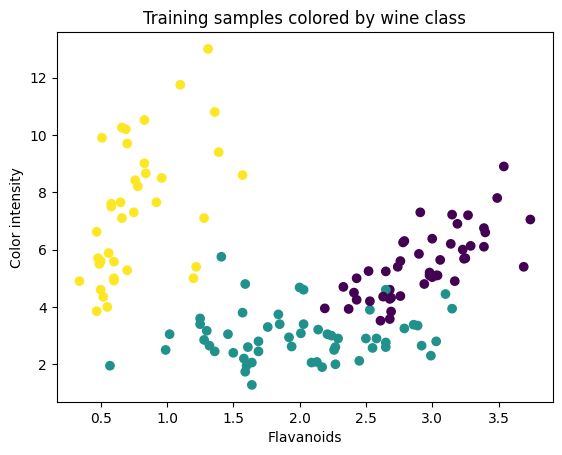

In [8]:
plt.scatter(X_train['flavanoids'], X_train['color_intensity'],
            c=y_train, cmap='viridis')
plt.xlabel('Flavanoids')
plt.ylabel('Color intensity')
plt.title('Training samples colored by wine class')
plt.show()

3 Compare the models
A random forest combines many decision trees. Each tree uses a random sample of training rows and a random selection of features at each split. Combining different trees usually reduces overfitting compared to using a single tree

To explain random forest simply: trees vote. scikit learn averages their probabilities and chooses the class with the highest average

I used five fold validation on the training data to select a model and each model trains on four folds and predicts the remaining. Repeated five times.

Logistic regressing and KNN used standard scaler because feature sizes affect them a lot. The tree models use the original values, and linear regression is not included because the target is a category/text not a number

In [6]:
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Logistic Regression': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    cv_scores[name] = scores.mean()

best_name = max(cv_scores, key=cv_scores.get)
print('Best training CV model:', best_name)
display(pd.DataFrame({'CV accuracy': cv_scores}).round(4))

Best training CV model: Random Forest


,CV accuracy
Random Forest,0.9512
Decision Tree,0.9163
Logistic Regression,0.9372
KNN,0.9507


4 Evaluate on the held out test set

The model is already fixed using training validation. Then I reported test accuracy for the comparison. I didn't change any features, settings ,or the model based on the test results.

This dataset is pretty tiny compared to others and should really only be used as a class example. A high score here doesn't prove the model would perform similarly on wines and numbers from other sources

,CV accuracy,Test accuracy
Random Forest,0.9512,0.9722
Decision Tree,0.9163,0.9722
Logistic Regression,0.9372,0.8333
KNN,0.9507,0.9444


Selected model: Random Forest
Test accuracy: 0.9722222222222222
              precision    recall  f1-score   support

Wine Class 1       0.92      1.00      0.96        12
Wine Class 2       1.00      0.93      0.96        14
Wine Class 3       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



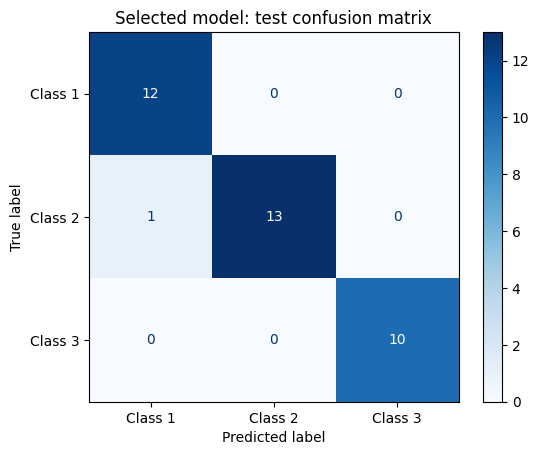

In [7]:
test_scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    test_scores[name] = accuracy_score(y_test, model.predict(X_test))

results = pd.DataFrame({
    'CV accuracy': cv_scores,
    'Test accuracy': test_scores
})
display(results.round(4))

best_model = models[best_name]
predictions = best_model.predict(X_test)
print('Selected model:', best_name)
print('Test accuracy:', accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions,
      target_names=['Wine Class 1', 'Wine Class 2', 'Wine Class 3']))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=['Class 1', 'Class 2', 'Class 3'],
    cmap='Blues')
plt.title('Selected model: test confusion matrix')
plt.show()

5 Save and reload the selected model

If a scaled model winds, it's saved pipeline also contains its fitted scaler. I kept the three input columns in the same order when predicting.

The app uses the original inputs, and random forest didn't need any scaling or dummy variables. I saved the real test examples so I can demonstrate the app using actual data values

In [9]:
api_folder = Path('wine_api')
api_folder.mkdir(exist_ok=True)
with open(api_folder / 'model.pkl', 'wb') as file:
    pickle.dump(best_model, file)
with open(api_folder / 'model.pkl', 'rb') as file:
    saved_model = pickle.load(file)

assert np.array_equal(predictions, saved_model.predict(X_test))
print('Reloaded model returns the same test predictions.')

examples = []
for wine_class in sorted(y_test.unique()):
    row_id = y_test[y_test == wine_class].index[0]
    values = X_test.loc[row_id].to_dict()
    predicted = int(saved_model.predict(pd.DataFrame([values], columns=features))[0])
    examples.append({
        'csv_row_index': int(row_id),
        'inputs': values,
        'actual_class': int(wine_class) + 1,
        'predicted_class': predicted + 1
    })
with open(api_folder / 'examples.json', 'w') as file:
    json.dump(examples, file, indent=2)

report = {
    'selected_model': best_name,
    'train_rows': len(X_train), 'test_rows': len(X_test),
    'cv_accuracy': cv_scores, 'test_accuracy': test_scores,
    'examples': examples
}
with open('results.json', 'w') as file:
    json.dump(report, file, indent=2)
display(pd.DataFrame(examples))

Reloaded model returns the same test predictions.


,csv_row_index,inputs,actual_class,predicted_class
0,10,"{'alcohol': 14.1, 'flavanoids': 3.32, 'color_i...",1,1
1,121,"{'alcohol': 11.56, 'flavanoids': 5.08, 'color_...",2,2
2,134,"{'alcohol': 12.51, 'flavanoids': 0.58, 'color_...",3,3


Conclusion
Random forest had the highest training accuract in this run, although KNN was very close. That small different doesn't establish that RF is better per se. The printed test accuract shows whether this run exceeds the 80% target. The flask app loads the saved model and provides both a web and json prediction endpoint.